# Part 1: Longitudinal Data Analysis in a Pediatric Birth Cohort
### Statistical Programmer portfolio, TPG / NICHD-style health study (R)

**Setting.** A synthetic birth cohort of 800 children measured at birth and at 6, 12, 24, 36 and 60 months. Outcomes: **BMI z-score** (continuous), **neurodevelopmental delay** (repeated binary) and **time to first asthma diagnosis** (survival). Exposure: a standardized prenatal factor. Visits are missed, children drop out, and visit times are irregular, as in a real cohort. All data are synthetic.

**What this notebook demonstrates**

| Section | Methods |
|---|---|
| 1-2 | Cohort simulation, attrition, descriptive trajectories |
| 3 | Linear mixed models (random intercept, random slope), covariance structures (CAR(1)), diagnostics, GAMM |
| 4 | Marginal (GEE) vs conditional (GLMM) models for a repeated binary outcome |
| 5 | Missing data: complete-case, multiple imputation (MAR), delta-adjusted tipping-point analysis (MNAR) |
| 6 | Survival: Cox model with trajectory-derived predictors, and a deep survival network |
| 7 | **Neural networks**: GRU sequence model (with deep ensembles and conformal intervals) compared with the mixed model for dynamic prediction |

**Neural networks are competitors here, not replacements.** The question asked of every network is whether it beats the classical model once small samples, uncertainty and interpretability are taken into account. All networks are implemented from scratch in base R (backpropagation, AdamW, dropout, early stopping) and verified by gradient checking, so nothing beyond standard R packages is needed.

In [1]:
## Setup: packages, folders, helper for saving figures
need <- c("lme4", "geepack", "mice", "survival", "mgcv", "nlme")
miss <- need[!vapply(need, requireNamespace, logical(1), quietly = TRUE)]
if (length(miss)) install.packages(miss, repos = "https://cloud.r-project.org")
suppressPackageStartupMessages({ library(lme4); library(nlme); library(mgcv); library(geepack); library(mice); library(survival) })
dir.create("PIC", showWarnings = FALSE)
options(width = 110, digits = 4)

## fig(): draw a base-graphics plot, save it to PIC/<name>.png and show it in the notebook
fig <- function(name, expr, w = 7, h = 4.5) {
  f <- file.path("PIC", paste0(name, ".png"))
  png(f, width = w, height = h, units = "in", res = 110)
  tryCatch(expr, finally = dev.off())
  if (isTRUE(getOption("knitr.in.progress"))) return(knitr::include_graphics(f))
  if (requireNamespace("IRdisplay", quietly = TRUE)) invisible(IRdisplay::display_png(file = f)) else invisible(f)
}
cat("R", as.character(getRversion()), "| lme4", as.character(packageVersion("lme4")), "| mice", as.character(packageVersion("mice")), "\n")

R 4.3.3 | lme4 1.1.35.1 | mice 3.16.0 


## 1. Synthetic cohort

Each child has a random intercept and a random slope for BMI z-score, so children differ in both starting level and growth rate. The prenatal exposure speeds growth (true effect: +0.10 z per year per SD, so **+0.50 z by age 5**), which gives a known target to check estimators against. Residuals are correlated over time (continuous-time AR(1)), visits are jittered, some visits are missed at random, and children drop out in a way that depends on their *observed* BMI z-score (missing at random, MAR). The binary outcome has a child-level random effect, and the asthma time-to-event depends on the child's true growth slope.

In [2]:
set.seed(2025)
N <- 800
visit_months <- c(0, 6, 12, 24, 36, 60)
kids <- data.frame(id = 1:N, male = rbinom(N, 1, 0.51), exposure = rnorm(N),
                   mat_bmi = rnorm(N, 27, 5), breastfed = rbinom(N, 1, 0.6))
kids$mat_bmi_c <- (kids$mat_bmi - 27) / 5
sd_b <- c(0.8, 0.25); rho_b <- -0.2
u0 <- rnorm(N); u1 <- rho_b * u0 + sqrt(1 - rho_b^2) * rnorm(N)
kids$b0 <- sd_b[1] * u0; kids$b1 <- sd_b[2] * u1            # random intercept and slope (per year)

TRUE_EXPOSURE_SLOPE <- 0.10; sig_e <- 0.5; rho_e <- 0.5
rows <- list()
for (i in 1:N) {
  k <- kids[i, ]
  mo <- visit_months + c(0, runif(5, -0.5, 0.5)); tt <- mo / 12
  mu <- (0.1 + 0.10 * k$male + 0.25 * k$mat_bmi_c + k$b0) +
        (0.05 + TRUE_EXPOSURE_SLOPE * k$exposure - 0.08 * k$breastfed + k$b1) * tt - 0.02 * tt^2
  e <- numeric(6); e[1] <- rnorm(1, 0, sig_e)
  for (j in 2:6) { ph <- rho_e^(tt[j] - tt[j - 1]); e[j] <- ph * e[j - 1] + sqrt(1 - ph^2) * rnorm(1, 0, sig_e) }
  z <- mu + e
  obs <- rep(FALSE, 6); active <- TRUE
  for (j in 1:6) {
    if (j == 1) { obs[j] <- TRUE; next }
    if (active) {                                        # monotone dropout depends on last observed z (MAR)
      last <- max(which(obs)); if (runif(1) < plogis(-2.7 + 0.5 * z[last] + 0.2 * k$male)) active <- FALSE
    }
    obs[j] <- active && (runif(1) > 0.10)                # plus intermittent missed visits
  }
  rows[[i]] <- data.frame(id = i, visit = 1:6, months = mo, t = tt, z_true = z, z = ifelse(obs, z, NA), observed = obs, in_study_dummy = TRUE)
}
long <- do.call(rbind, rows)
long <- merge(long, kids, by = "id"); long <- long[order(long$id, long$visit), ]

## repeated binary outcome: neurodevelopmental delay at visits 3-6
set.seed(2026)
u_delay <- rnorm(N, 0, 1.2)
long$delay <- NA
idx <- long$visit >= 3 & long$observed
eta <- -2.2 + 0.35 * long$exposure + 0.4 * long$male - 0.3 * long$breastfed + u_delay[long$id]
long$delay[idx] <- rbinom(sum(idx), 1, plogis(eta[idx]))

## time to first asthma diagnosis (Weibull), linked to the child's true growth slope
set.seed(2027)
eta_s <- 0.3 * kids$exposure + 0.25 * kids$male - 0.2 * kids$breastfed + 0.6 * (kids$b1 / sd_b[2])
shape <- 1.3; scale0 <- 0.0125
T_event <- (-log(runif(N)) / (scale0 * exp(eta_s)))^(1 / shape)
C_time <- runif(N, 4, 10)
surv <- data.frame(id = 1:N, time = pmin(T_event, C_time), status = as.integer(T_event <= C_time))
surv <- merge(surv, kids[, c("id", "male", "exposure", "mat_bmi_c", "breastfed")], by = "id")

cat("children:", N, "| rows (child-visits):", nrow(long), "| observed measurements:", sum(long$observed), "\n")
cat("asthma events:", sum(surv$status), sprintf("(%.0f%%)", 100 * mean(surv$status)), "| delay prevalence among observed visits:", sprintf("%.1f%%", 100 * mean(long$delay, na.rm = TRUE)), "\n")
head(long[long$id <= 2, c("id", "visit", "months", "z", "observed", "male", "exposure", "breastfed", "delay")], 8)

children: 800 | rows (child-visits): 4800 | observed measurements: 3656 
asthma events: 125 (16%) | delay prevalence among observed visits: 15.1% 
  id visit months        z observed male exposure breastfed delay
1  1     1  0.000  0.07344     TRUE    0  0.04178         0    NA
2  1     2  5.513  0.17693     TRUE    0  0.04178         0    NA
3  1     3 11.818  0.29987     TRUE    0  0.04178         0     0
4  1     4 24.358  0.83028     TRUE    0  0.04178         0     1
5  1     5 35.947  0.13113     TRUE    0  0.04178         0     0
6  1     6 60.415 -0.36619     TRUE    0  0.04178         0     0
7  2     1  0.000  1.50326     TRUE    1 -0.81362         0    NA
8  2     2  6.168  1.44889     TRUE    1 -0.81362         0    NA


## 2. Descriptive analysis: attrition and trajectories

Before modeling, look at how much data each visit really has and what the raw trajectories look like. Retention and the shape of the average curve guide the modeling choices below.

 visit_months n_observed pct_of_cohort mean_z sd_z
            0        800         100.0   0.14 0.99
            6        663          82.9   0.11 0.98
           12        598          74.8   0.04 0.99
           24        573          71.6  -0.01 1.03
           36        534          66.8  -0.22 1.19
           60        488          61.0  -0.60 1.52


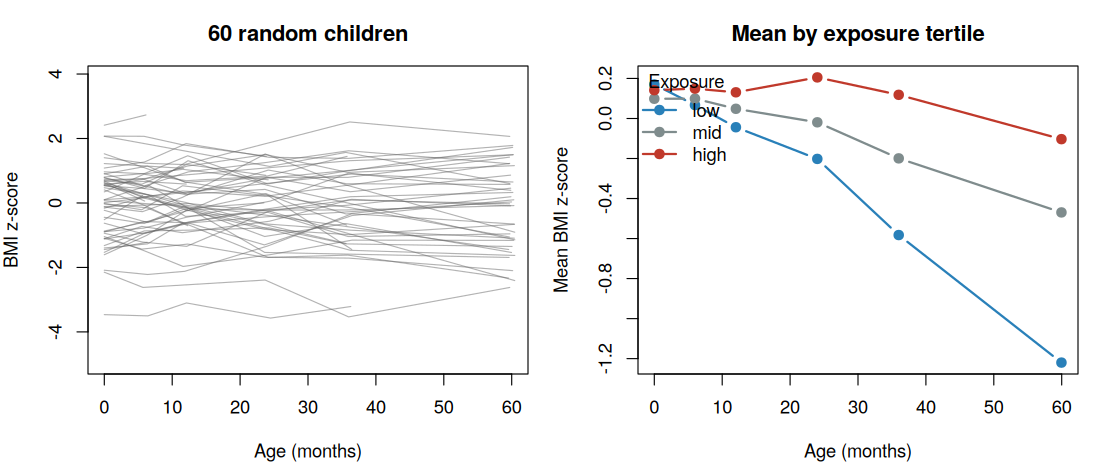

In [3]:
vis_tab <- data.frame(visit_months = visit_months,
                      n_observed = tapply(long$observed, long$visit, sum),
                      pct_of_cohort = round(100 * tapply(long$observed, long$visit, mean), 1))
vis_tab$mean_z <- round(tapply(long$z, long$visit, mean, na.rm = TRUE), 2)
vis_tab$sd_z <- round(tapply(long$z, long$visit, sd, na.rm = TRUE), 2)
print(vis_tab, row.names = FALSE)

obs <- subset(long, observed)
obs$exp_grp <- cut(obs$exposure, quantile(kids$exposure, c(0, 1/3, 2/3, 1)), labels = c("low", "mid", "high"), include.lowest = TRUE)
fig("p1_01_trajectories", {
  par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  plot(NA, xlim = c(0, 60), ylim = range(obs$z), xlab = "Age (months)", ylab = "BMI z-score", main = "60 random children")
  for (i in sample(N, 60)) { d <- obs[obs$id == i, ]; lines(d$months, d$z, col = adjustcolor("grey40", 0.5)) }
  cols <- c(low = "#2980b9", mid = "#7f8c8d", high = "#c0392b")
  mz <- aggregate(z ~ visit + exp_grp, obs, mean); mm <- aggregate(months ~ visit, obs, mean)
  plot(NA, xlim = c(0, 60), ylim = range(mz$z), xlab = "Age (months)", ylab = "Mean BMI z-score", main = "Mean by exposure tertile")
  for (g in names(cols)) { d <- mz[mz$exp_grp == g, ]; lines(mm$months, d$z, type = "b", pch = 19, col = cols[g], lwd = 2) }
  legend("topleft", legend = names(cols), col = cols, pch = 19, lwd = 2, title = "Exposure", bty = "n")
}, w = 10, h = 4.2)

## 3. Linear mixed models

A **linear mixed model (LMM)** models each child's own line while estimating population effects. The key choices: which random effects (intercept only, or intercept and slope), and which residual correlation structure. Models are compared by likelihood-ratio test (fitted with ML) and by AIC/BIC; the final model is refit by REML for unbiased variance components.

In [4]:
f_fixed <- z ~ male + mat_bmi_c + exposure * t + breastfed * t + I(t^2)
m_ri <- lmer(update(f_fixed, . ~ . + (1 | id)),     data = obs, REML = FALSE)
m_rs <- lmer(update(f_fixed, . ~ . + (1 + t | id)), data = obs, REML = FALSE)
cat("Likelihood-ratio test: random intercept vs random intercept + slope\n")
print(anova(m_ri, m_rs))

m_final <- update(m_rs, REML = TRUE)
fe <- summary(m_final)$coefficients
ci <- confint(m_final, parm = "beta_", method = "Wald")
tab <- data.frame(estimate = fe[, 1], lower = ci[, 1], upper = ci[, 2], t = fe[, 3])
cat("\nFixed effects, final model (REML), 95% Wald CI\n"); print(round(tab, 3))
cat(sprintf("\nTrue exposure-by-time effect: %.2f | estimated: %.3f (95%% CI %.3f to %.3f)\n",
            TRUE_EXPOSURE_SLOPE, tab["exposure:t", "estimate"], tab["exposure:t", "lower"], tab["exposure:t", "upper"]))
cat("\nVariance components\n"); print(VarCorr(m_final), digits = 3)

Likelihood-ratio test: random intercept vs random intercept + slope
Data: obs
Models:
m_ri: z ~ male + mat_bmi_c + exposure + t + breastfed + I(t^2) + (1 | id) + exposure:t + t:breastfed
m_rs: z ~ male + mat_bmi_c + exposure + t + breastfed + I(t^2) + (1 + t | id) + exposure:t + t:breastfed
     npar  AIC  BIC logLik deviance Chisq Df Pr(>Chisq)    
m_ri   11 8138 8206  -4058     8116                        
m_rs   13 6625 6705  -3299     6599  1517  2     <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Fixed effects, final model (REML), 95% Wald CI
            estimate  lower  upper      t
(Intercept)    0.120  0.003  0.236  2.007
male           0.107 -0.017  0.232  1.687
mat_bmi_c      0.302  0.241  0.362  9.794
exposure      -0.029 -0.093  0.035 -0.882
t              0.052  0.010  0.093  2.453
breastfed     -0.044 -0.178  0.089 -0.652
I(t^2)        -0.022 -0.027 -0.017 -8.683
exposure:t     0.104  0.082  0.125  9.464
t:breastfed   -0.091 -0.135 -0.046 

### Residual correlation structure

Repeated measures on the same child are correlated, and the correlation decays as visits get further apart. With irregular visit times, **continuous-time AR(1) (CAR1)** is the natural choice. This block compares covariance structures with `nlme`, which supports them directly.

In [5]:
ctrl <- lmeControl(maxIter = 200, msMaxIter = 200, opt = "optim")
g1 <- lme(z ~ male + mat_bmi_c + exposure * t + breastfed * t + I(t^2), random = ~ 1 | id, data = obs, method = "ML", control = ctrl)
g2 <- update(g1, correlation = corCAR1(form = ~ t | id))
g3 <- update(g1, random = ~ t | id)
g4 <- update(g3, correlation = corCAR1(form = ~ t | id))
cmp <- AIC(g1, g2, g3, g4); cmp$BIC <- BIC(g1, g2, g3, g4)$BIC
cmp$structure <- c("random intercept, independent errors", "random intercept + CAR(1) errors",
                   "random intercept + slope, independent errors", "random intercept + slope + CAR(1) errors")
cmp <- cmp[, c("structure", "df", "AIC", "BIC")]; cmp$AIC <- round(cmp$AIC, 1); cmp$BIC <- round(cmp$BIC, 1)
print(cmp, row.names = FALSE)
cat("\nCAR(1) correlation parameter (per year) in the last model:", round(coef(g4$modelStruct$corStruct, unconstrained = FALSE), 3), "\n")
cat("True value used to generate the data:", rho_e, "\n")

                                    structure df  AIC  BIC
         random intercept, independent errors 11 8138 8206
             random intercept + CAR(1) errors 12 6541 6615
 random intercept + slope, independent errors 13 6625 6705
     random intercept + slope + CAR(1) errors 14 6343 6430

CAR(1) correlation parameter (per year) in the last model: 0.457 
True value used to generate the data: 0.5 


### Model diagnostics

A model that fits well should show residuals with no pattern, approximately normal residuals, and approximately normal random effects. Departures here would mean the linear-in-time structure or the normality assumption needs revisiting.

Shapiro-Wilk on random slopes: p = 0.00771 


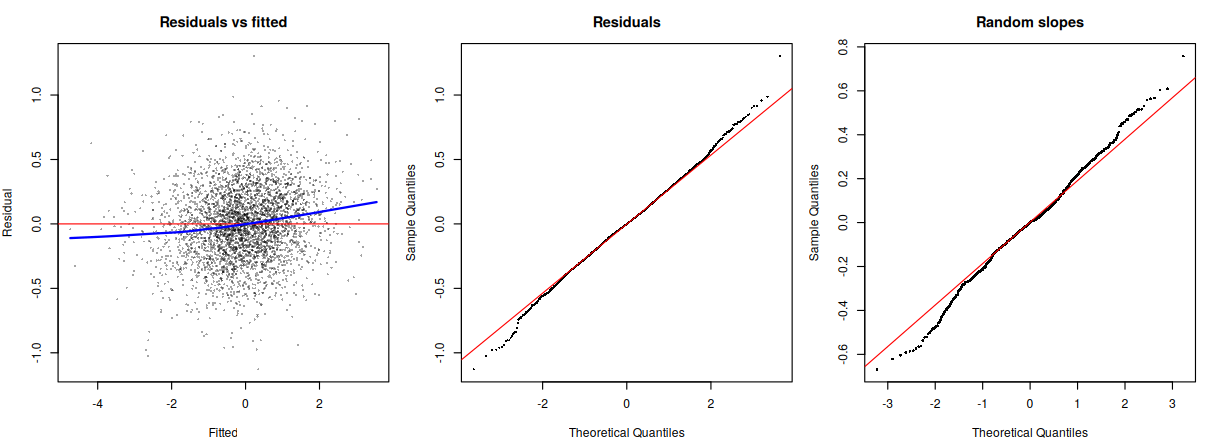

In [6]:
fig("p1_02_lmm_diagnostics", {
  par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
  r <- resid(m_final); f <- fitted(m_final)
  plot(f, r, pch = 16, cex = 0.4, col = adjustcolor("black", 0.35), xlab = "Fitted", ylab = "Residual", main = "Residuals vs fitted")
  abline(h = 0, col = "red"); lines(lowess(f, r), col = "blue", lwd = 2)
  qqnorm(r, pch = 16, cex = 0.4, main = "Residuals"); qqline(r, col = "red")
  re <- ranef(m_final)$id
  qqnorm(re[, "t"], pch = 16, cex = 0.5, main = "Random slopes"); qqline(re[, "t"], col = "red")
}, w = 11, h = 4)
cat("Shapiro-Wilk on random slopes: p =", signif(shapiro.test(ranef(m_final)$id[, "t"])$p.value, 3), "\n")

### Nonlinear trajectory: GAMM

If the true curve is not a quadratic, a **generalized additive mixed model (GAMM)** lets the data choose the shape. Here a smooth function of age is combined with a random intercept per child (`bs = "re"`), including a random slope. The model is fitted with `bam`, mgcv's memory-efficient fitter for many random-effect levels. The estimated mean curve is compared with the quadratic LMM.

Parametric terms
            Estimate Std. Error t value Pr(>|t|)
(Intercept)   -0.025      0.063  -0.392    0.695
male           0.100      0.066   1.521    0.128
mat_bmi_c      0.292      0.032   9.177    0.000
exposure       0.201      0.039   5.197    0.000
breastfed     -0.063      0.067  -0.951    0.342

Smooth terms (edf = effective degrees of freedom; edf near 1 means a straight line)
                  edf  Ref.df      F p-value
s(t)            3.226   3.656  41.01       0
s(t):exposure   1.000   1.000  91.00       0
s(id_f)       741.283 800.000 252.33       0
s(t,id_f)     546.032 727.000 263.86       0

Mean BMI z of a typical child at each age: GAMM vs quadratic LMM
 age_years   GAMM    LMM difference
       0.5  0.135  0.140     -0.005
       1.0  0.120  0.122     -0.002
       2.0  0.069  0.053      0.016
       3.0 -0.054 -0.060      0.007
       4.0 -0.215 -0.218      0.003
       5.0 -0.390 -0.419      0.029


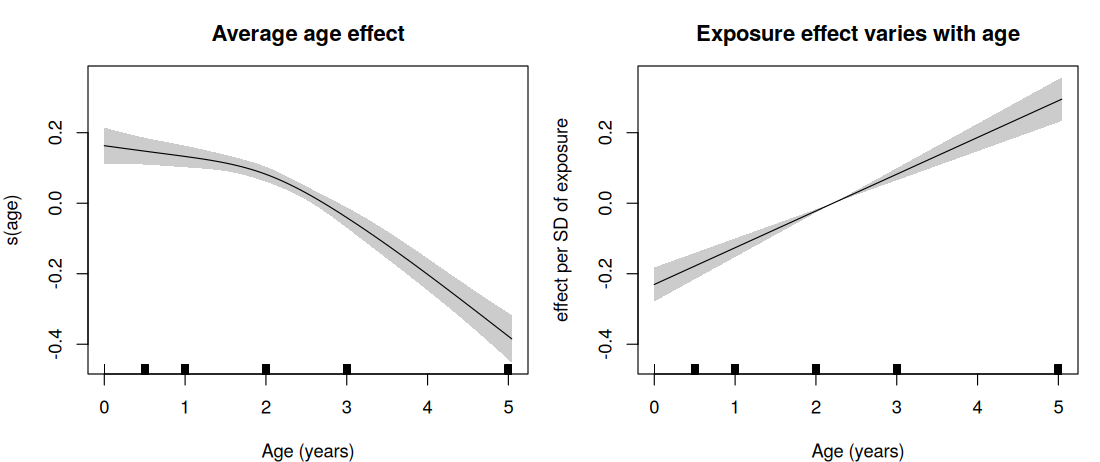

In [7]:
obs$id_f <- factor(obs$id)            # random effects in mgcv need a factor
g_gam <- bam(z ~ male + mat_bmi_c + exposure + breastfed + s(t, k = 5) + s(t, by = exposure, k = 4) +
               s(id_f, bs = "re") + s(id_f, t, bs = "re"), data = obs, method = "fREML", discrete = TRUE)   # bam: efficient for many random-effect levels
sm <- summary(g_gam)
cat("Parametric terms\n"); print(round(sm$p.table, 3))
cat("\nSmooth terms (edf = effective degrees of freedom; edf near 1 means a straight line)\n"); print(round(sm$s.table, 3))
## population-level mean curve: GAMM vs quadratic LMM, for a typical child (all covariates at their means)
ages <- c(0.5, 1, 2, 3, 4, 5); ref <- data.frame(male = 0.5, mat_bmi_c = 0, exposure = 0, breastfed = 0.6, t = ages, id_f = obs$id_f[1])
re_terms <- grep("id_f", sapply(g_gam$smooth, function(x) x$label), value = TRUE)
p_gam <- predict(g_gam, ref, exclude = re_terms, newdata.guaranteed = TRUE)
p_lmm <- as.numeric(model.matrix(~ male + mat_bmi_c + exposure * t + breastfed * t + I(t^2), cbind(ref, z = 0)) %*% fixef(m_final))
cat("\nMean BMI z of a typical child at each age: GAMM vs quadratic LMM\n")
print(round(data.frame(age_years = ages, GAMM = as.numeric(p_gam), LMM = p_lmm, difference = as.numeric(p_gam) - p_lmm), 3), row.names = FALSE)
fig("p1_03_gamm_smooth", {
  par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
  plot(g_gam, select = 1, shade = TRUE, xlab = "Age (years)", ylab = "s(age)", main = "Average age effect")
  plot(g_gam, select = 2, shade = TRUE, xlab = "Age (years)", ylab = "effect per SD of exposure", main = "Exposure effect varies with age")
}, w = 10, h = 4.2)

## 4. Repeated binary outcome: marginal vs conditional models

For a repeated binary outcome (neurodevelopmental delay), two modeling philosophies answer different questions.

- **GEE** (generalized estimating equations) estimates **population-average (marginal)** effects, with robust standard errors that stay valid even if the working correlation is wrong.
- **GLMM** (generalized linear mixed model) estimates **child-specific (conditional)** effects given a child-level random effect.

For logistic models these odds ratios are not the same: the conditional OR is further from 1 than the marginal OR when the random-effect variance is large. Neither is "wrong"; they answer different questions.

In [8]:
bin <- subset(long, !is.na(delay)); bin <- bin[order(bin$id, bin$visit), ]
gee_ex <- geeglm(delay ~ exposure + male + breastfed, id = id, data = bin, family = binomial, corstr = "exchangeable")
gee_in <- geeglm(delay ~ exposure + male + breastfed, id = id, data = bin, family = binomial, corstr = "independence")
glmm <- suppressWarnings(glmer(delay ~ exposure + male + breastfed + (1 | id), data = bin, family = binomial, nAGQ = 1))

or_tab <- function(co, se) data.frame(OR = exp(co), lower = exp(co - 1.96 * se), upper = exp(co + 1.96 * se))
s1 <- summary(gee_ex)$coefficients; s2 <- summary(gee_in)$coefficients; s3 <- summary(glmm)$coefficients
res <- rbind(cbind(model = "GEE exchangeable (marginal)", term = rownames(s1)[-1], or_tab(s1[-1, 1], s1[-1, 2])),
             cbind(model = "GEE independence (marginal)", term = rownames(s2)[-1], or_tab(s2[-1, 1], s2[-1, 2])),
             cbind(model = "GLMM random intercept (conditional)", term = rownames(s3)[-1], or_tab(s3[-1, 1], s3[-1, 2])))
res[, 3:5] <- round(res[, 3:5], 3); rownames(res) <- NULL
print(res)
cat("\nRandom-intercept SD (estimated):", round(attr(VarCorr(glmm)$id, "stddev"), 3), "| true: 1.2\n")
cat("True conditional exposure OR:", round(exp(0.35), 3), "| attenuated marginal OR expected near", round(exp(0.35 / sqrt(1 + 0.346 * 1.2^2)), 3), "\n")

                                model      term    OR lower upper
1         GEE exchangeable (marginal)  exposure 1.369 1.204 1.555
2         GEE exchangeable (marginal)      male 0.871 0.666 1.139
3         GEE exchangeable (marginal) breastfed 0.880 0.668 1.159
4         GEE independence (marginal)  exposure 1.376 1.211 1.564
5         GEE independence (marginal)      male 0.866 0.662 1.133
6         GEE independence (marginal) breastfed 0.892 0.677 1.176
7 GLMM random intercept (conditional)  exposure 1.434 1.226 1.677
8 GLMM random intercept (conditional)      male 0.873 0.643 1.185
9 GLMM random intercept (conditional) breastfed 0.859 0.629 1.175

Random-intercept SD (estimated): 1.01 | true: 1.2
True conditional exposure OR: 1.419 | attenuated marginal OR expected near 1.331 


## 5. Missing data

About a third of children are gone by 60 months, and dropout depends on earlier BMI. Analyses must say what they assume about the missing values.

1. **Complete-case:** use only children with a 60-month measurement. Valid only if dropout is unrelated to the outcome, which is not the case here.
2. **Mixed model on all available data:** valid under MAR, because the likelihood uses every observation.
3. **Multiple imputation (MI):** impute missing 60-month values from earlier visits and covariates, analyze each completed dataset, combine with Rubin's rules.
4. **Delta-adjusted tipping-point analysis (MNAR):** assume dropouts follow a different exposure-outcome relationship than the imputation model implies, and ask how different it would have to be to change the conclusion.

The target is the exposure effect on BMI z-score at 60 months; the true value is **0.50 per SD** (0.10 per year over 5 years).

In [9]:
wide <- reshape(long[, c("id", "visit", "z")], idvar = "id", timevar = "visit", direction = "wide")
names(wide) <- c("id", paste0("z", c(0, 6, 12, 24, 36, 60)))
wide <- merge(wide, kids[, c("id", "male", "exposure", "mat_bmi_c", "breastfed")], by = "id")
miss_tab <- data.frame(visit = c(0, 6, 12, 24, 36, 60), pct_missing = round(100 * colMeans(is.na(wide[, paste0("z", c(0, 6, 12, 24, 36, 60))])), 1))
print(miss_tab, row.names = FALSE)

## (1) complete-case, (2) mixed model on all data
cc <- lm(z60 ~ exposure + male + breastfed + mat_bmi_c, data = wide)
cc_est <- c(coef(cc)["exposure"], confint(cc)["exposure", ])
lmm_effect <- tab["exposure:t", c("estimate", "lower", "upper")] * 5     # slope effect over 5 years

## (3) multiple imputation
set.seed(11)
imp <- mice(wide[, -1], m = 20, maxit = 10, method = "norm", printFlag = FALSE)
comp <- complete(imp, "all")
rubin <- function(fits, term = "exposure") {
  q <- sapply(fits, function(f) coef(f)[term]); u <- sapply(fits, function(f) vcov(f)[term, term]); m <- length(fits)
  qb <- mean(q); tv <- mean(u) + (1 + 1 / m) * var(q); c(est = qb, lower = qb - qt(0.975, m - 1) * sqrt(tv), upper = qb + qt(0.975, m - 1) * sqrt(tv), se = sqrt(tv))
}
fits <- lapply(comp, function(d) lm(z60 ~ exposure + male + breastfed + mat_bmi_c, data = d))
mi_est <- rubin(fits)

summ <- rbind("Complete-case" = cc_est, "LMM, all data (MAR)" = as.numeric(lmm_effect), "Multiple imputation (MAR)" = mi_est[1:3])
colnames(summ) <- c("estimate", "lower", "upper")
cat("\nExposure effect on BMI z at 60 months (truth = 0.50)\n"); print(round(summ, 3))

 visit pct_missing
     0         0.0
     6        17.1
    12        25.2
    24        28.4
    36        33.2
    60        39.0

Exposure effect on BMI z at 60 months (truth = 0.50)
                          estimate lower upper
Complete-case                0.490 0.367 0.614
LMM, all data (MAR)          0.518 0.411 0.626
Multiple imputation (MAR)    0.479 0.358 0.600


### Tipping-point analysis

A constant shift applied to every dropout would barely move an exposure effect, so the sensitivity parameter must act on the exposure itself. Here each imputed 60-month value for a dropout is shifted by **δ times that child's exposure**: δ is the amount by which the exposure effect among dropouts differs from what the imputation model assumed (in z-score units per SD of exposure). If the overall effect stays clearly positive across a plausible range of δ, the conclusion is robust to departures from MAR. The **tipping point** is the δ at which the 95% confidence interval first includes zero.

 delta estimate  lower  upper
 -1.50   -0.156 -0.289 -0.022
 -1.25   -0.050 -0.180  0.080
 -1.00    0.056 -0.071  0.182
 -0.75    0.161  0.037  0.286
 -0.50    0.267  0.145  0.390
 -0.25    0.373  0.251  0.494
  0.00    0.479  0.358  0.600
  0.25    0.584  0.463  0.706
  0.50    0.690  0.568  0.812
  0.75    0.796  0.672  0.920
  1.00    0.901  0.775  1.028
  1.25    1.007  0.878  1.136
  1.50    1.113  0.980  1.245

Tipping point: the 95% CI includes 0 for delta between -1.25 and -1 (delta = 0 is the MAR assumption)


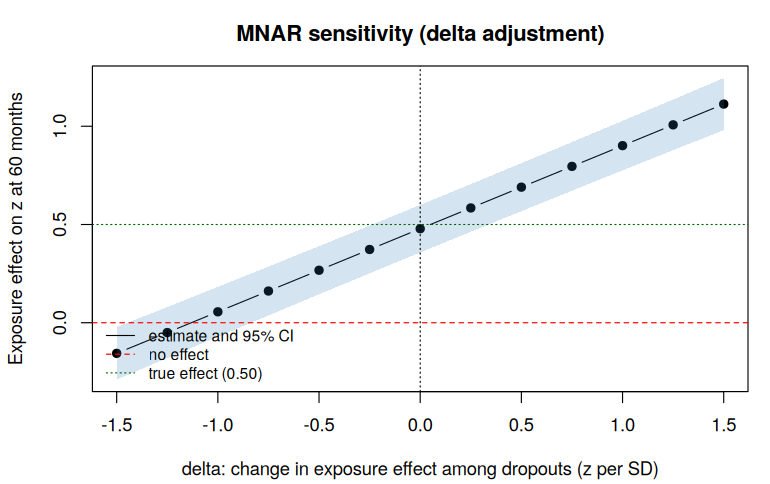

In [10]:
miss60 <- is.na(wide$z60)
deltas <- seq(-1.5, 1.5, by = 0.25)
tp <- t(sapply(deltas, function(dl) {
  fts <- lapply(comp, function(d) { d$z60[miss60] <- d$z60[miss60] + dl * d$exposure[miss60]; lm(z60 ~ exposure + male + breastfed + mat_bmi_c, data = d) })
  rubin(fts)
}))
tp <- data.frame(delta = deltas, tp[, 1:3]); names(tp) <- c("delta", "estimate", "lower", "upper")
print(round(tp, 3), row.names = FALSE)
cross <- tp$delta[tp$lower <= 0 & tp$upper >= 0]
cat("\nTipping point: the 95% CI includes 0 for delta between", if (length(cross)) paste(min(cross), "and", max(cross)) else "no values in range", "(delta = 0 is the MAR assumption)\n")
fig("p1_04_tipping_point", {
  par(mar = c(4.2, 4.2, 3, 1))
  plot(tp$delta, tp$estimate, type = "b", pch = 19, ylim = range(c(tp$lower, tp$upper, 0)), xlab = "delta: change in exposure effect among dropouts (z per SD)", ylab = "Exposure effect on z at 60 months", main = "MNAR sensitivity (delta adjustment)")
  polygon(c(tp$delta, rev(tp$delta)), c(tp$lower, rev(tp$upper)), col = adjustcolor("#2980b9", 0.2), border = NA)
  abline(h = 0, lty = 2, col = "red"); abline(h = 0.5, lty = 3, col = "darkgreen"); abline(v = 0, lty = 3)
  legend("bottomleft", c("estimate and 95% CI", "no effect", "true effect (0.50)"), lty = c(1, 2, 3), col = c("black", "red", "darkgreen"), bty = "n", cex = 0.85)
}, w = 7, h = 4.4)

## 6. Neural-network toolkit

The networks used from here on are written from scratch in base R, so the notebook needs no deep-learning installation. The toolkit has a multilayer perceptron with backpropagation, AdamW (decoupled weight decay), dropout and early stopping; negative log-likelihood losses for regression, binary outcomes and the **Cox partial likelihood**; and a **GRU** (gated recurrent unit) with hand-written back-propagation through time. The next cell loads it, and the one after verifies every gradient numerically.

In [11]:
## ---- Neural-network toolkit in base R (backpropagation, AdamW, dropout, early stopping) ----
sigmoid <- function(x) 1 / (1 + exp(-x))

## AdamW optimizer: params P and gradients G are named lists of arrays
adam_new <- function(P) list(m = lapply(P, function(a) a * 0), v = lapply(P, function(a) a * 0), t = 0)
adam_update <- function(P, G, S, lr = 1e-3, wd = 0, b1 = 0.9, b2 = 0.999, eps = 1e-8) {
  S$t <- S$t + 1
  for (nm in names(P)) {
    S$m[[nm]] <- b1 * S$m[[nm]] + (1 - b1) * G[[nm]]
    S$v[[nm]] <- b2 * S$v[[nm]] + (1 - b2) * G[[nm]]^2
    mh <- S$m[[nm]] / (1 - b1^S$t); vh <- S$v[[nm]] / (1 - b2^S$t)
    P[[nm]] <- P[[nm]] - lr * mh / (sqrt(vh) + eps)
    if (wd > 0 && grepl("^[WU]", nm)) P[[nm]] <- P[[nm]] - lr * wd * P[[nm]]   # decoupled weight decay
  }
  list(P = P, S = S)
}

## Multilayer perceptron: sizes = c(input, hidden..., output); linear output layer
mlp_init <- function(sizes, seed = 1, last_scale = 1) {     # last_scale < 1 starts the output layer near zero (useful for wide autoencoders)
  set.seed(seed); P <- list()
  for (l in seq_len(length(sizes) - 1)) {
    P[[paste0("W", l)]] <- matrix(rnorm(sizes[l] * sizes[l + 1], 0, sqrt(2 / sizes[l])), sizes[l], sizes[l + 1])
    P[[paste0("b", l)]] <- rep(0, sizes[l + 1])
  }
  Ll <- length(sizes) - 1; P[[paste0("W", Ll)]] <- P[[paste0("W", Ll)]] * last_scale
  P
}
mlp_forward <- function(P, X, drop_in = 0, drop_hid = 0, train = FALSE, act = "relu") {
  L <- sum(grepl("^W", names(P))); H <- X
  cache <- list(inputs = vector("list", L), pre = vector("list", L), masks = vector("list", L + 1))
  if (train && drop_in > 0) { m <- (matrix(runif(length(H)), nrow(H)) > drop_in) / (1 - drop_in); H <- H * m; cache$masks[[1]] <- m }
  for (l in seq_len(L)) {
    cache$inputs[[l]] <- H
    b <- P[[paste0("b", l)]]
    Z <- H %*% P[[paste0("W", l)]] + matrix(b, nrow(H), length(b), byrow = TRUE)
    cache$pre[[l]] <- Z
    if (l < L) {
      H <- if (act == "relu") pmax(Z, 0) else tanh(Z)
      if (train && drop_hid > 0) { m <- (matrix(runif(length(H)), nrow(H)) > drop_hid) / (1 - drop_hid); H <- H * m; cache$masks[[l + 1]] <- m }
    } else H <- Z
  }
  list(out = H, cache = cache)
}
mlp_backward <- function(P, fw, dout, act = "relu") {
  L <- sum(grepl("^W", names(P))); G <- list(); d <- dout; dX <- NULL
  for (l in L:1) {
    G[[paste0("W", l)]] <- crossprod(fw$cache$inputs[[l]], d)
    G[[paste0("b", l)]] <- colSums(d)
    dH <- d %*% t(P[[paste0("W", l)]])
    m <- fw$cache$masks[[l]]
    if (!is.null(m)) dH <- dH * m
    if (l > 1) {
      Z <- fw$cache$pre[[l - 1]]
      d <- dH * (if (act == "relu") (Z > 0) else (1 - tanh(Z)^2))
    } else dX <- dH
  }
  list(G = G, dX = dX)
}

## Losses: each returns the loss value and its gradient with respect to the network output
loss_mse <- function(out, y) { y <- as.matrix(y); list(loss = mean((out - y)^2), dout = 2 * (out - y) / length(y)) }
loss_bce <- function(out, y) {                     # binary cross-entropy on logits
  y <- as.matrix(y); p <- sigmoid(out)
  list(loss = mean(pmax(out, 0) - out * y + log1p(exp(-abs(out)))), dout = (p - y) / length(y))
}
loss_cox <- function(out, y) {                     # negative Cox partial log-likelihood; y = cbind(time, status)
  eta <- as.numeric(out); time <- y[, 1]; status <- y[, 2]; n <- length(eta)
  o <- order(time, decreasing = TRUE); e <- exp(eta - max(eta))
  S <- numeric(n); S[o] <- cumsum(e[o])             # risk-set sum: all subjects with time >= t_i
  ll <- sum(status * (eta - max(eta) - log(S))) 
  inc <- numeric(n); inc[o] <- status[o] / S[o]
  oa <- order(time); A <- numeric(n); A[oa] <- cumsum(inc[oa])   # sum over events k with t_k <= t_i of 1/S_k
  grad <- -status + e * A
  nev <- max(sum(status), 1)
  list(loss = -ll / nev, dout = matrix(grad / nev, ncol = 1))
}

## Generic trainer: minibatch AdamW, dropout, early stopping on a validation set, optional group-lasso proximal step
mlp_fit <- function(X, y, sizes, loss = loss_bce, epochs = 200, batch = 64, lr = 1e-3, wd = 1e-3,
                    drop_in = 0, drop_hid = 0, act = "relu", prox = 0,
                    Xval = NULL, yval = NULL, patience = 20, seed = 1, full_batch = FALSE, last_scale = 1) {
  P <- mlp_init(sizes, seed, last_scale); S <- adam_new(P); set.seed(seed + 1000)
  n <- nrow(X); best <- Inf; bestP <- P; wait <- 0; hist <- NULL
  if (full_batch) batch <- n
  for (ep in seq_len(epochs)) {
    idx <- sample(n); tr <- 0
    for (s in seq(1, n, by = batch)) {
      b <- idx[s:min(s + batch - 1, n)]
      if (length(b) < 2) next
      fw <- mlp_forward(P, X[b, , drop = FALSE], drop_in, drop_hid, train = TRUE, act = act)
      yb <- if (is.matrix(y)) y[b, , drop = FALSE] else y[b]
      ls <- loss(fw$out, yb); tr <- tr + ls$loss * length(b)
      bw <- mlp_backward(P, fw, ls$dout, act)
      up <- adam_update(P, bw$G, S, lr, wd); P <- up$P; S <- up$S
      if (prox > 0) {                               # group soft-threshold of each input feature's outgoing weights
        nr <- sqrt(rowSums(P$W1^2)); P$W1 <- P$W1 * pmax(0, 1 - lr * prox / pmax(nr, 1e-12))
      }
    }
    vl <- if (!is.null(Xval)) loss(mlp_forward(P, Xval, act = act)$out, yval)$loss else tr / n
    hist <- rbind(hist, data.frame(epoch = ep, train = tr / n, val = vl))
    if (vl < best - 1e-6) { best <- vl; bestP <- P; wait <- 0 } else { wait <- wait + 1; if (wait >= patience) break }
  }
  list(P = bestP, hist = hist, best_epoch = hist$epoch[which.min(hist$val)], act = act)
}
mlp_predict <- function(fit, X) mlp_forward(fit$P, X, act = fit$act)$out

## Integrated Gradients attribution for a scalar-output network (baseline = 0 = the feature mean after standardization)
integrated_gradients <- function(fit, X, steps = 20) {
  Gs <- X * 0
  for (s in seq_len(steps)) {
    fw <- mlp_forward(fit$P, X * ((s - 0.5) / steps), act = fit$act)
    Gs <- Gs + mlp_backward(fit$P, fw, matrix(1, nrow(X), 1), fit$act)$dX
  }
  X * Gs / steps
}

## Rank-based AUC and Harrell's concordance helpers
auc_rank <- function(y, score) { r <- rank(score); n1 <- sum(y == 1); n0 <- sum(y == 0); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0) }

In [12]:
## ---- GRU sequence model with manual back-propagation through time ----
## Inputs per time step: x_t = (value, observed-mask, time-gap); static covariates S join the final hidden state.
gru_init <- function(d, h, head_sizes, seed = 1) {
  set.seed(seed); g <- function(i, o) matrix(rnorm(i * o, 0, sqrt(1 / i)), i, o)
  list(gru = list(Wz = g(d, h), Uz = g(h, h), bz = rep(0, h), Wr = g(d, h), Ur = g(h, h), br = rep(0, h),
                  Wn = g(d, h), Un = g(h, h), bn = rep(0, h)),
       head = mlp_init(head_sizes, seed + 7))
}
gru_forward <- function(Pg, Xseq, h) {                    # Xseq: array [n, T, d]
  n <- dim(Xseq)[1]; Tn <- dim(Xseq)[2]; H <- matrix(0, n, h); ch <- vector("list", Tn)
  bm <- function(b) matrix(b, n, length(b), byrow = TRUE)
  for (t in seq_len(Tn)) {
    x <- Xseq[, t, ]; if (is.null(dim(x))) x <- matrix(x, n)
    z <- sigmoid(x %*% Pg$Wz + H %*% Pg$Uz + bm(Pg$bz))
    r <- sigmoid(x %*% Pg$Wr + H %*% Pg$Ur + bm(Pg$br))
    hu <- H %*% Pg$Un
    nn <- tanh(x %*% Pg$Wn + r * hu + bm(Pg$bn))
    ch[[t]] <- list(x = x, H = H, z = z, r = r, hu = hu, nn = nn)
    H <- (1 - z) * nn + z * H
  }
  list(h = H, cache = ch)
}
gru_backward <- function(Pg, cache, dH) {
  G <- lapply(Pg, function(a) a * 0)
  for (t in rev(seq_along(cache))) {
    c <- cache[[t]]
    dn <- dH * (1 - c$z); dz <- dH * (c$H - c$nn); dHp <- dH * c$z
    dan <- dn * (1 - c$nn^2)
    G$Wn <- G$Wn + crossprod(c$x, dan); G$bn <- G$bn + colSums(dan)
    dr <- dan * c$hu
    G$Un <- G$Un + crossprod(c$H, dan * c$r); dHp <- dHp + (dan * c$r) %*% t(Pg$Un)
    daz <- dz * c$z * (1 - c$z)
    G$Wz <- G$Wz + crossprod(c$x, daz); G$Uz <- G$Uz + crossprod(c$H, daz); G$bz <- G$bz + colSums(daz)
    dHp <- dHp + daz %*% t(Pg$Uz)
    dar <- dr * c$r * (1 - c$r)
    G$Wr <- G$Wr + crossprod(c$x, dar); G$Ur <- G$Ur + crossprod(c$H, dar); G$br <- G$br + colSums(dar)
    dH <- dHp + dar %*% t(Pg$Ur)
  }
  G
}
gru_loss_grad <- function(Pall, Xseq, S, y, h, drop = 0, train = FALSE) {
  fg <- gru_forward(Pall$gru, Xseq, h)
  fh <- mlp_forward(Pall$head, cbind(fg$h, S), drop_in = drop, train = train)
  ls <- loss_mse(fh$out, y)
  bh <- mlp_backward(Pall$head, fh, ls$dout)
  Gg <- gru_backward(Pall$gru, fg$cache, bh$dX[, 1:h, drop = FALSE])
  list(loss = ls$loss, G = list(gru = Gg, head = bh$G), out = fh$out)
}
gru_fit <- function(Xseq, S, y, Xseq_v, S_v, y_v, h = 12, head = c(16, 1), epochs = 200, batch = 64,
                    lr = 3e-3, wd = 1e-3, drop = 0.1, patience = 20, seed = 1) {
  d <- dim(Xseq)[3]; P <- gru_init(d, h, c(h + ncol(S), head), seed)
  Sg <- adam_new(P$gru); Sh <- adam_new(P$head); set.seed(seed + 1000)
  n <- nrow(S); best <- Inf; bestP <- P; wait <- 0; hist <- NULL
  for (ep in seq_len(epochs)) {
    idx <- sample(n); tr <- 0
    for (s in seq(1, n, by = batch)) {
      b <- idx[s:min(s + batch - 1, n)]; if (length(b) < 2) next
      r <- gru_loss_grad(P, Xseq[b, , , drop = FALSE], S[b, , drop = FALSE], y[b], h, drop, TRUE)
      tr <- tr + r$loss * length(b)
      ug <- adam_update(P$gru, r$G$gru, Sg, lr, wd); P$gru <- ug$P; Sg <- ug$S
      uh <- adam_update(P$head, r$G$head, Sh, lr, wd); P$head <- uh$P; Sh <- uh$S
    }
    vl <- gru_loss_grad(P, Xseq_v, S_v, y_v, h)$loss
    hist <- rbind(hist, data.frame(epoch = ep, train = tr / n, val = vl))
    if (vl < best - 1e-6) { best <- vl; bestP <- P; wait <- 0 } else { wait <- wait + 1; if (wait >= patience) break }
  }
  list(P = bestP, h = h, hist = hist)
}
gru_predict <- function(fit, Xseq, S, mc = 0, drop = 0.1) {
  fg <- gru_forward(fit$P$gru, Xseq, fit$h); Z <- cbind(fg$h, S)
  if (mc == 0) return(as.numeric(mlp_forward(fit$P$head, Z)$out))
  sapply(seq_len(mc), function(i) as.numeric(mlp_forward(fit$P$head, Z, drop_in = drop, train = TRUE)$out))
}

In [13]:
## Gradient checking: compare analytic gradients with central finite differences (relative error should be tiny)
set.seed(3)
Xg <- matrix(rnorm(30 * 5), 30, 5); yg <- rnorm(30)
chk <- function(P, G, f) { mx <- 0
  for (nm in names(P)) for (k in sample(length(P[[nm]]), min(5, length(P[[nm]])))) {
    e <- 1e-6; P2 <- P; P2[[nm]][k] <- P2[[nm]][k] + e; P3 <- P; P3[[nm]][k] <- P3[[nm]][k] - e
    num <- (f(P2) - f(P3)) / (2 * e); an <- G[[nm]][k]; mx <- max(mx, abs(num - an) / max(1e-8, abs(num) + abs(an))) }
  mx }
Pm <- mlp_init(c(5, 6, 4, 1), 2); fw <- mlp_forward(Pm, Xg)
cat("MLP (MSE loss):         max relative gradient error =", signif(chk(Pm, mlp_backward(Pm, fw, loss_mse(fw$out, yg)$dout)$G, function(P) loss_mse(mlp_forward(P, Xg)$out, yg)$loss), 3), "\n")
yy <- cbind(rexp(30), rbinom(30, 1, 0.7)); Pc <- mlp_init(c(5, 4, 1), 5); fw <- mlp_forward(Pc, Xg)
cat("MLP (Cox partial lik.): max relative gradient error =", signif(chk(Pc, mlp_backward(Pc, fw, loss_cox(fw$out, yy)$dout)$G, function(P) loss_cox(mlp_forward(P, Xg)$out, yy)$loss), 3), "\n")
Xs <- array(rnorm(10 * 4 * 3), c(10, 4, 3)); Ss <- matrix(rnorm(10 * 2), 10); ys <- rnorm(10)
Pg <- gru_init(3, 5, c(7, 4, 1), 9); rr <- gru_loss_grad(Pg, Xs, Ss, ys, 5); mx <- 0
for (grp in c("gru", "head")) for (nm in names(Pg[[grp]])) for (k in sample(length(Pg[[grp]][[nm]]), min(4, length(Pg[[grp]][[nm]])))) {
  e <- 1e-6; P2 <- Pg; P2[[grp]][[nm]][k] <- P2[[grp]][[nm]][k] + e; P3 <- Pg; P3[[grp]][[nm]][k] <- P3[[grp]][[nm]][k] - e
  num <- (gru_loss_grad(P2, Xs, Ss, ys, 5)$loss - gru_loss_grad(P3, Xs, Ss, ys, 5)$loss) / (2 * e); an <- rr$G[[grp]][[nm]][k]
  mx <- max(mx, abs(num - an) / max(1e-8, abs(num) + abs(an))) }
cat("GRU (BPTT):             max relative gradient error =", signif(mx, 3), "\n")

MLP (MSE loss):         max relative gradient error = 9.88e-09 
MLP (Cox partial lik.): max relative gradient error = 2.48e-09 
GRU (BPTT):             max relative gradient error = 2.19e-07 


## 7. Deep survival: time to asthma

A **Cox proportional hazards** model is the standard tool. Its neural counterpart (**DeepSurv**) replaces the linear predictor with a network trained on the same partial likelihood. Predictors are the baseline covariates plus the child's **early growth trajectory**, summarized by the random intercept and slope (BLUPs) from a mixed model fitted on visits up to 24 months only (no information from after 24 months, and none from the asthma outcome). Performance is the cross-validated **concordance index** (C-index; 0.5 is chance, 1.0 is perfect).

In [14]:
early <- subset(obs, months <= 25)
m_early <- lmer(z ~ male + mat_bmi_c + exposure * t + breastfed * t + (1 + t | id), data = early, REML = TRUE)
re <- ranef(m_early)$id; re$id <- as.integer(rownames(re))
sv <- merge(surv, setNames(re, c("b0_hat", "b1_hat", "id")), by = "id"); sv <- sv[order(sv$id), ]
cat("Correlation between estimated and true random slope:", round(cor(sv$b1_hat, kids$b1[sv$id]), 3), "\n")

feat_base <- c("exposure", "male", "breastfed", "mat_bmi_c"); feat_full <- c(feat_base, "b0_hat", "b1_hat")
cindex <- function(time, status, lp) unname(concordance(Surv(time, status) ~ lp, reverse = TRUE)$concordance)

set.seed(5); folds <- sample(rep(1:5, length.out = nrow(sv)))
res <- NULL
for (k in 1:5) {
  tr <- sv[folds != k, ]; te <- sv[folds == k, ]
  c0 <- coxph(Surv(time, status) ~ ., data = tr[, c("time", "status", feat_base)])
  c1 <- coxph(Surv(time, status) ~ ., data = tr[, c("time", "status", feat_full)])
  mu <- colMeans(tr[, feat_full]); sdv <- apply(tr[, feat_full], 2, sd)
  sc <- function(d) scale(d[, feat_full], center = mu, scale = sdv)
  vi <- sample(nrow(tr), round(0.2 * nrow(tr)))
  ens <- lapply(1:5, function(s) mlp_fit(sc(tr)[-vi, ], cbind(tr$time, tr$status)[-vi, ], c(length(feat_full), 16, 8, 1), loss_cox,
                                         epochs = 300, lr = 3e-3, wd = 1e-2, drop_hid = 0.2, full_batch = TRUE, patience = 30, seed = s,
                                         Xval = sc(tr)[vi, ], yval = cbind(tr$time, tr$status)[vi, ]))
  lp_nn <- rowMeans(sapply(ens, function(f) as.numeric(mlp_predict(f, sc(te)))))
  res <- rbind(res, data.frame(fold = k,
    cox_baseline = cindex(te$time, te$status, predict(c0, te)),
    cox_with_trajectory = cindex(te$time, te$status, predict(c1, te)),
    deepsurv_with_trajectory = cindex(te$time, te$status, lp_nn)))
}
cat("5-fold cross-validated C-index by fold\n"); print(round(res, 3), row.names = FALSE)
sm <- data.frame(model = names(res)[-1], mean_C = colMeans(res[, -1]), sd_across_folds = apply(res[, -1], 2, sd))
cat("\nSummary\n"); print(format(sm, digits = 3), row.names = FALSE)
cfull <- coxph(Surv(time, status) ~ ., data = sv[, c("time", "status", feat_full)])
cat("\nCox model with trajectory features (all data)\n"); print(round(summary(cfull)$coefficients[, c(1, 2, 3, 5)], 3))
cat("\nProportional-hazards test (cox.zph) global p-value:", signif(cox.zph(cfull)$table["GLOBAL", "p"], 3), "\n")

Correlation between estimated and true random slope: 0.511 
5-fold cross-validated C-index by fold
 fold cox_baseline cox_with_trajectory deepsurv_with_trajectory
    1        0.565               0.541                    0.623
    2        0.653               0.638                    0.624
    3        0.581               0.622                    0.574
    4        0.527               0.476                    0.511
    5        0.530               0.583                    0.551

Summary
                    model mean_C sd_across_folds
             cox_baseline  0.571          0.0512
      cox_with_trajectory  0.572          0.0655
 deepsurv_with_trajectory  0.576          0.0485

Cox model with trajectory features (all data)
            coef exp(coef) se(coef) Pr(>|z|)
exposure   0.259     1.295    0.090    0.004
male       0.158     1.172    0.181    0.382
breastfed -0.252     0.777    0.181    0.164
mat_bmi_c  0.080     1.084    0.086    0.353
b0_hat    -0.054     0.947    0.104    0

## 8. Dynamic prediction of BMI z-score at 60 months: mixed model vs GRU

**Task.** Using a child's visits up to 24 months (birth, 6, 12, 24) plus covariates, predict BMI z-score at 60 months. This is *dynamic prediction*: the same question a clinician asks when deciding who needs early intervention.

**Competitors.**
- **Last observation carried forward (LOCF):** a naive baseline.
- **Linear mixed model:** the classical answer. For a test child, the model is fitted using that child's early visits only, and the prediction uses the child's estimated random effects.
- **GRU:** a recurrent network reading the 4 visits with inputs (z-score, observed-or-missed indicator, time since last visit). Five GRUs with different seeds are averaged (a *deep ensemble*).

**Uncertainty.** Both methods get **split-conformal prediction intervals** (90%): residuals on a held-out calibration set set the interval width. Coverage should be near 90%; narrower intervals at the same coverage are better.

**Protocol.** 5-fold cross-validation, always splitting by child. In each fold, a calibration set (15%) and validation set (15%, for early stopping) are carved from the training children. Test children contribute early visits only.

In [15]:
grid_m <- c(0, 6, 12, 24)
early_long <- subset(long, visit <= 4)
Xarr <- array(0, c(N, 4, 3)); 
zz <- matrix(NA, N, 4); for (v in 1:4) zz[, v] <- early_long$z[early_long$visit == v][order(early_long$id[early_long$visit == v])]
mu_z <- mean(zz, na.rm = TRUE); sd_z <- sd(zz, na.rm = TRUE)
for (i in 1:N) {
  last <- NA; last_t <- 0
  for (v in 1:4) {
    ob <- !is.na(zz[i, v]); tnow <- grid_m[v] / 12
    if (ob) { last <- (zz[i, v] - mu_z) / sd_z; last_t <- tnow }
    Xarr[i, v, ] <- c(if (is.na(last)) 0 else last, as.numeric(ob), tnow - last_t)
  }
}
S_mat <- as.matrix(kids[, c("male", "exposure", "mat_bmi_c", "breastfed")]); S_mat <- scale(S_mat)
y60 <- wide$z60; has60 <- !is.na(y60)
locf <- sapply(1:N, function(i) { o <- which(!is.na(zz[i, ])); if (length(o)) zz[i, max(o)] else mu_z })
cat("children with an observed 60-month outcome:", sum(has60), "of", N, "\n")
cat("input array:", paste(dim(Xarr), collapse = " x "), "(children x visits x [value, observed, time-gap])\n")

children with an observed 60-month outcome: 488 of 800 
input array: 800 x 4 x 3 (children x visits x [value, observed, time-gap])


In [16]:
set.seed(21)
fold_id <- sample(rep(1:5, length.out = N))
q_conf <- function(res, alpha = 0.10) { n <- length(res); sort(abs(res))[min(n, ceiling((n + 1) * (1 - alpha)))] }
out <- NULL; curves <- NULL
t0 <- Sys.time()
for (k in 1:5) {
  test <- which(fold_id == k & has60); trn_all <- which(fold_id != k)
  trn <- trn_all[has60[trn_all]]; sh <- sample(trn)
  nc <- round(0.15 * length(sh)); nv <- round(0.15 * length(sh))
  cal <- sh[1:nc]; val <- sh[(nc + 1):(nc + nv)]; fit_idx <- sh[-(1:(nc + nv))]
  ## --- mixed model: early visits only for test and calibration children, all visits for the others ---
  hold <- union(which(fold_id == k), cal)
  dat <- subset(obs, !(id %in% hold) | months <= 25)
  mk <- lmer(z ~ male + mat_bmi_c + exposure * t + breastfed * t + I(t^2) + (1 + t | id), data = dat, REML = TRUE)
  nd <- long[long$id %in% c(test, cal) & long$visit == 6, ]; nd$t <- 60 / 12
  p_lmm <- setNames(predict(mk, newdata = nd, re.form = NULL, allow.new.levels = FALSE), nd$id)
  ## --- GRU deep ensemble: trained on fit_idx, early stopping on val ---
  gp <- sapply(1:5, function(s) {
    g <- gru_fit(Xarr[fit_idx, , , drop = FALSE], S_mat[fit_idx, , drop = FALSE], (y60[fit_idx] - mu_z) / sd_z,
                 Xarr[val, , , drop = FALSE], S_mat[val, , drop = FALSE], (y60[val] - mu_z) / sd_z, h = 12, seed = s)
    if (s == 1 && k == 1) curves <<- g$hist
    gru_predict(g, Xarr[c(test, cal), , , drop = FALSE], S_mat[c(test, cal), , drop = FALSE]) * sd_z + mu_z
  })
  rownames(gp) <- c(test, cal)
  p_gru <- rowMeans(gp); p_single <- gp[, 1]
  for (nm in c("LOCF", "Mixed model", "GRU single", "GRU ensemble (5)")) {
    pr <- switch(nm, "LOCF" = setNames(locf[c(test, cal)], c(test, cal)), "Mixed model" = p_lmm[as.character(c(test, cal))],
                 "GRU single" = p_single, "GRU ensemble (5)" = p_gru)
    yt <- y60[test]; ptest <- pr[as.character(test)]; qh <- q_conf(y60[cal] - pr[as.character(cal)])
    out <- rbind(out, data.frame(fold = k, method = nm, id = test, obs = yt, pred = as.numeric(ptest), q = as.numeric(qh)))
  }
}
cat("elapsed:", round(as.numeric(difftime(Sys.time(), t0, units = "secs"))), "seconds\n")
met <- do.call(rbind, lapply(split(out, out$method), function(d) data.frame(
  RMSE = sqrt(mean((d$obs - d$pred)^2)), MAE = mean(abs(d$obs - d$pred)),
  coverage_90 = mean(abs(d$obs - d$pred) <= d$q), mean_width = 2 * mean(d$q))))
met <- met[c("LOCF", "Mixed model", "GRU single", "GRU ensemble (5)"), ]
cat("\nOut-of-fold performance, BMI z at 60 months (n =", length(unique(out$id)), "children)\n"); print(round(met, 3))
## paired bootstrap over children: RMSE difference GRU ensemble minus mixed model
bw <- reshape(out[, c("id", "method", "obs", "pred")], idvar = c("id", "obs"), timevar = "method", direction = "wide")
set.seed(9); dd <- replicate(2000, { i <- sample(nrow(bw), replace = TRUE)
  sqrt(mean((bw$obs[i] - bw[["pred.GRU ensemble (5)"]][i])^2)) - sqrt(mean((bw$obs[i] - bw[["pred.Mixed model"]][i])^2)) })
cat(sprintf("\nPaired bootstrap, RMSE(GRU ensemble) - RMSE(mixed model): %+.3f (95%% CI %+.3f to %+.3f)\n", mean(dd), quantile(dd, 0.025), quantile(dd, 0.975)))

elapsed: 18 seconds

Out-of-fold performance, BMI z at 60 months (n = 488 children)
                  RMSE   MAE coverage_90 mean_width
LOCF             1.147 0.918       0.914      3.978
Mixed model      0.982 0.785       0.920      3.423
GRU single       1.020 0.822       0.904      3.410
GRU ensemble (5) 0.999 0.808       0.922      3.451

Paired bootstrap, RMSE(GRU ensemble) - RMSE(mixed model): +0.017 (95% CI -0.019 to +0.053)


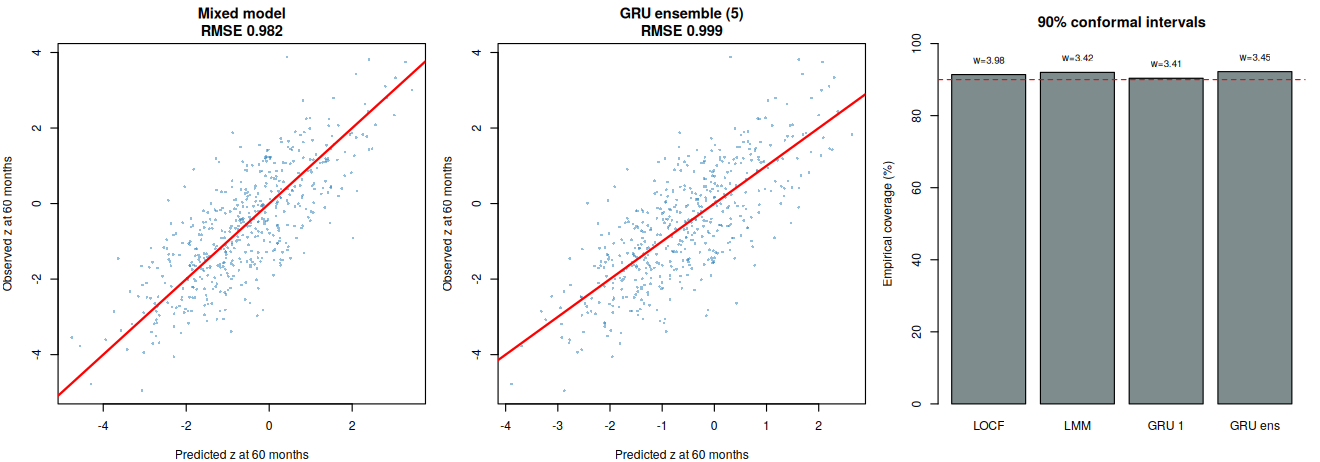

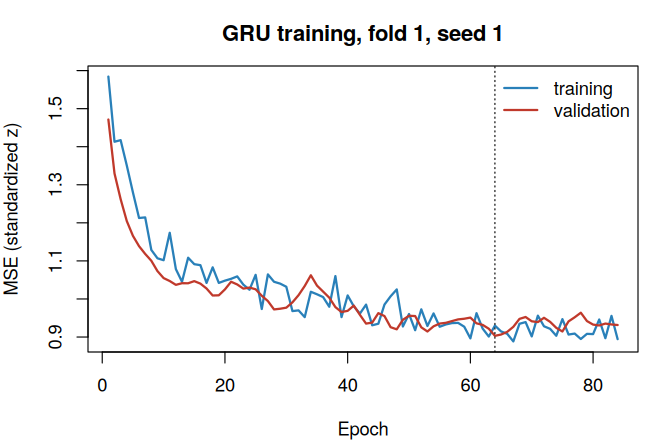

In [17]:
fig("p1_05_prediction", {
  par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
  for (nm in c("Mixed model", "GRU ensemble (5)")) {
    d <- out[out$method == nm, ]
    plot(d$pred, d$obs, pch = 16, cex = 0.5, col = adjustcolor("#2980b9", 0.5), xlab = "Predicted z at 60 months", ylab = "Observed z at 60 months",
         main = sprintf("%s\nRMSE %.3f", nm, sqrt(mean((d$obs - d$pred)^2))))
    abline(0, 1, col = "red", lwd = 2)
  }
  bp <- barplot(met$coverage_90 * 100, names.arg = c("LOCF", "LMM", "GRU 1", "GRU ens"), ylim = c(0, 100), col = "#7f8c8d", ylab = "Empirical coverage (%)", main = "90% conformal intervals")
  abline(h = 90, col = "red", lty = 2); text(bp, met$coverage_90 * 100 + 4, sprintf("w=%.2f", met$mean_width), cex = 0.8)
}, w = 12, h = 4.2)
fig("p1_06_gru_training", {
  par(mar = c(4, 4, 3, 1))
  plot(curves$epoch, curves$train, type = "l", col = "#2980b9", lwd = 2, ylim = range(c(curves$train, curves$val)), xlab = "Epoch", ylab = "MSE (standardized z)", main = "GRU training, fold 1, seed 1")
  lines(curves$epoch, curves$val, col = "#c0392b", lwd = 2); legend("topright", c("training", "validation"), col = c("#2980b9", "#c0392b"), lwd = 2, bty = "n")
  abline(v = curves$epoch[which.min(curves$val)], lty = 3)
}, w = 6, h = 4)

## 9. Summary and honest reading of the results

- **Longitudinal effects.** The mixed model recovers the true exposure-by-time effect, and the random-slope structure is clearly preferred over random intercept only. Continuous-time AR(1) residual correlation and the GAMM smooth are the natural extensions for irregular visits and curved trajectories.
- **Binary outcome.** GEE (marginal) and GLMM (conditional) odds ratios differ in the expected direction; the choice depends on whether the scientific question is about the population or about an individual child.
- **Missing data.** Complete-case analysis is biased when dropout depends on earlier outcomes. The mixed model and multiple imputation both use the observed data validly under MAR, and the tipping-point analysis shows how robust the conclusion is to MNAR departures.
- **Neural networks.** The deep survival network and the GRU are compared with strong classical baselines using the same folds and metrics. See the tables above: differences are small relative to their uncertainty. For a cohort of this size, with roughly linear growth and few visits, the mixed model is as accurate, gives interpretable effects, and is simpler to defend. Networks become more attractive with many visits, strongly nonlinear patterns and much larger samples.
- **Limitations.** Synthetic data with known structure; dropout is MAR by construction; the networks use fixed hyperparameters (no extensive tuning); conformal intervals assume exchangeable children.